# Spaceship titanic

Benvinguts a l'any 2912, on les vostres habilitats en ciència de dades són necessàries per resoldre un misteri còsmic. Hem rebut una transmissió des de quatre anys llum de distància i la situació no pinta gens bé.

La *Spaceship Titanic* era una nau de passatgers interestel·lar que va salpar fa un mes. Amb gairebé 13.000 passatgers a bord, la nau va emprendre el seu viatge inaugural transportant emigrants del nostre sistema solar cap a tres exoplanetes recentment habitables que orbiten estrelles properes.

Mentre vorejava Alpha Centauri, de camí cap a la seva primera destinació —el tòrrid 55 Cancri E—, la *Spaceship Titanic* va topar, per sorpresa, amb una anomalia espaciotemporal amagada dins d'un núvol de pols. Malauradament, va córrer una sort semblant a la del seu homònim de fa 1.000 anys. Tot i que la nau va romandre intacta, gairebé la meitat dels passatgers van ser transportats a una dimensió alternativa!

Font:
https://www.kaggle.com/competitions/spaceship-titanic/data

## Dataset Description

In this competition your task is to predict whether a passenger was transported to an alternate dimension during the Spaceship Titanic's collision with the spacetime anomaly. To help you make these predictions, you're given a set of personal records recovered from the ship's damaged computer system.
File and Data Field Descriptions

* train.csv - Personal records for about two-thirds (~8700) of the passengers, to be used as training data.
    * PassengerId - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is travelling with and pp is their number within the group. People in a group are often family members, but not always.
    * HomePlanet - The planet the passenger departed from, typically their planet of permanent residence.
    * CryoSleep - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
    * Cabin - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
    * Destination - The planet the passenger will be debarking to.
    * Age - The age of the passenger.
    * VIP - Whether the passenger has paid for special VIP service during the voyage.
    * RoomService, FoodCourt, ShoppingMall, Spa, VRDeck - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
    * Name - The first and last names of the passenger.
    * Transported - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.
* test.csv - Personal records for the remaining one-third (~4300) of the passengers, to be used as test data. Your task is to predict the value of Transported for the passengers in this set.
* sample_submission.csv - A submission file in the correct format.
    * PassengerId - Id for each passenger in the test set.
    * Transported - The target. For each passenger, predict either True or False.

## Descripció de la tasca

Aquesta competició de Kaggle que ha eixit fa poc planteja un problema de classificació binària: Si el passatger d'una nau espacial és enviat o no a una altra dimensió. 

Òbviament les dades són sintètiques, però no trivials. Els millors participans han aconseguit bons resultats, així que es suposa que funcionarà raonablement bé. 


In [47]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

df_original = pd.read_csv('train.csv')  
df_original.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [104]:
df = df_original.copy()

ids = np.array(df["PassengerId"].apply(lambda pId: pId.split("_")).to_list())
df["PId"] = ids[:,1]
df["PId"] = pd.to_numeric(df["PId"], errors="coerce")
df["GId"] = ids[:,0]
df["GId"] = pd.to_numeric(df["GId"], errors="coerce")

df.loc[df["Cabin"].isnull(),"Cabin"] = "_nodefinido_/_nodefinido_/_nodefinido_"
cabins = pd.DataFrame(df["Cabin"].apply(lambda pId: pId.split("/")).to_list(), columns=["deck","num","side"])
df["total_spend"] = np.log( df[["RoomService","FoodCourt","ShoppingMall","Spa","VRDeck"]].sum(axis=1) +1 ) # fem el logaritme per tenir les dades acotades

df.loc[df["Name"].isnull(),"Name"] = "_nodefinido_"
names = pd.DataFrame(df["Name"].apply(lambda pId: pId.split(" ")).to_list(), columns=["name","surname"])

df = pd.concat([df,cabins,names], axis=1)
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,Name,Transported,PId,GId,total_spend,deck,num,side,name,surname
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,Maham Ofracculy,False,1,1,0.000000,B,0,P,Maham,Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,Juanna Vines,True,1,2,6.602588,F,0,S,Juanna,Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,Altark Susent,False,1,3,9.248021,A,0,S,Altark,Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,Solam Susent,False,2,3,8.551981,A,0,S,Solam,Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,Willy Santantines,True,1,4,6.995766,F,1,S,Willy,Santantines


In [105]:
df.surname.value_counts()

surname
Casonston     18
Oneiles       16
Domington     15
Litthews      15
Fulloydez     14
              ..
Maglible       1
Valing         1
Curry          1
Halexandez     1
Goods          1
Name: count, Length: 2217, dtype: int64

<Axes: xlabel='total_spend', ylabel='Count'>

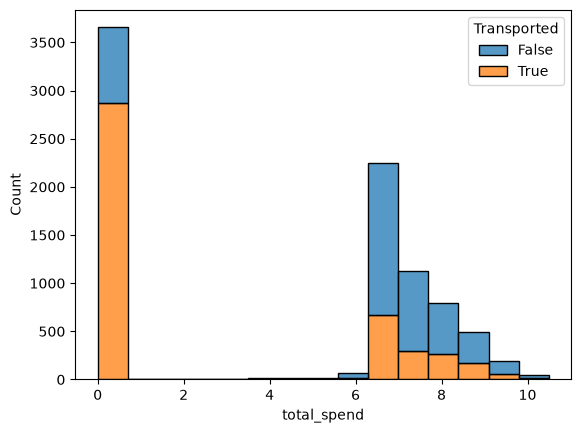

In [94]:

sns.histplot(data=df, x="total_spend", hue="Transported", multiple="stack")

<Axes: xlabel='total_spend', ylabel='Count'>

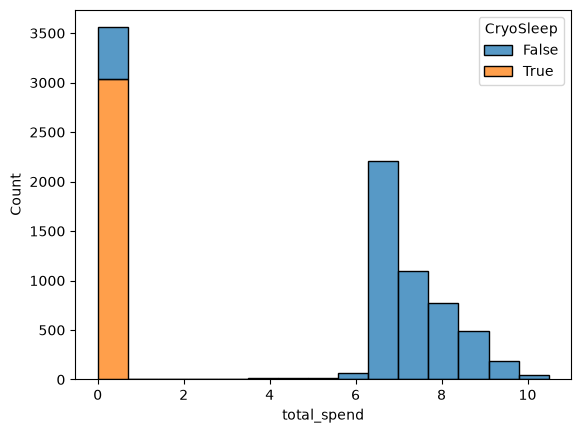

In [97]:
sns.histplot(data=df, x="total_spend", hue="CryoSleep", multiple="stack")

<Axes: xlabel='CryoSleep', ylabel='Count'>

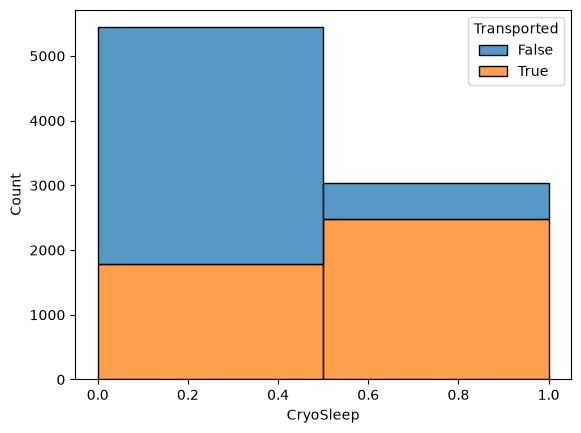

In [99]:
sns.histplot(data=df, x="CryoSleep", hue="Transported", multiple="stack", bins=2)

Hi ha molta gent que no ha gastat res, la majoria dels que no gasten són els criogenitzats dels qual tots han gastat 0. Els que gasten ho fan la majoria a partir de certa quantitat. 

La majoria dels que no han gastat res han sigut transportats. 

La majoria dels criogenitzats han sigut transportats. No sabem si per la seua situació o per no gastar. 

Exercici 1:

Raona les millors adaptacions que es poden fer al dataset per aprofitar millor l'informació disponible. Pensa en les columnes extra que es poden extraure i en què fer amb les dades que falten. Pensa per a què podrien servir les dades de test.csv si no tenen target.    

Exercici 2: 

Fes un anàlisi de les distintes correlacions entre les variables i l'objectiu. Interpreta quines variables podrien servir en cas d'una classificació amb mètodes lineals. Fes un anàlisi de la distribució de les variables en relació a la variable target. 

Exercici 3: 

Fes entrenaments lleugers de models simples de totes les famílies com `Gaussian Naive Bayes`, `LogisticRegression` o `DecisionTreeClassifier`. Interpreta els resultats de `classification_report` en relació al tipus de model. 

Exercici 4: 

Tria algun dels models moderns basats en ensembles d'arbres de classificació. Pots fer proves i/o justificar l'elecció en base al tipus de problemes per al quals estan dissenyats i el tipus i quantitat de dades. 
Planifica un entrenament amb tot: Pipelines, adaptacions del dataset, CV, Grid Search, entrenament final, mètriques i interpretació de totes les mètriques. 


Exercici 5:

Fes un anàlisi SHAP de l'importància i influència de les variables. 